# Lecture 25 notebook: choosing the markets

This notebook replays Lecture 25. Every figure and number of the lecture comes from a script in `scripts/`, next to this notebook; each runs in a fresh process. The data are free: daily adjusted closes and volume of 116 US-listed ETFs from Yahoo Finance (`scripts/l25_fetch.py`), downloaded once into `data/portfolio` (not committed).

By default the notebook downloads the data if they are missing, reruns the quick scripts (a few minutes) into a separate folder, redraws every figure of the lecture as `figures/nb_*.png`, and compares the recomputed numbers with the shipped ones in `results/`. `RUN_ALL` also reruns the screen of all seven methods and the out-of-sample comparisons (about an hour). Recomputed results never overwrite the shipped ones. Yahoo revises adjusted prices when funds pay distributions, so a download made later can differ slightly from ours; the comparisons show by how much.

| § | Content | Lecture |
|---|---|---|
| 0 | Settings and data | §2.1 |
| 1 | 116 ETFs, a few bets: the key chart and Table 1.1 | §1 |
| 2 | Synchronous closes: Table 2.2 | §2.2 |
| 3 | Correlation, factors and noise, with hand checks | §3 |
| 4 | The same market: concordance and trend strength, with hand checks | §4 |
| 5 | The methods as a family | §5 |
| 6 | Slots per class | §6 |
| 7 | Filling the slots: the score, out of sample | §7 |
| 8 | A roadmap for growing capital | §8 |
| 9 | A test of your own | |

## 0. Settings and data

In [1]:
import json, os, shutil, subprocess, sys, time
from pathlib import Path
import numpy as np, pandas as pd
from IPython.display import Image, display

HERE = Path.cwd(); SCRIPTS, FIG = HERE / "scripts", HERE / "figures"
sys.path[:0] = [str(SCRIPTS)]
import l25 as L
RUN_ALL = False                                                            # True: also rerun the screen and the out-of-sample comparisons (about an hour)

SHIPPED = HERE / "results"; WORK = L.DATA / "l25_results"                 # recomputed results go to WORK, never over the shipped ones
if not WORK.exists(): shutil.copytree(SHIPPED, WORK)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 20)
print("data:", L.RAW, "| shipped results:", SHIPPED, "| recomputed results:", WORK)


def run(script, *args, show=False):
    "Run a script of this lecture in a fresh process; figures as nb_*, results to WORK."
    t0 = time.time()
    env = {**os.environ, "PORTFOLIO_DATA": str(L.DATA), "L25_RESULTS": str(WORK), "L25_PREFIX": "nb_", "PYTHONIOENCODING": "utf-8"}
    p = subprocess.run([sys.executable, str(SCRIPTS / script), *args], capture_output=True, text=True, encoding="utf-8", env=env)
    if p.returncode:
        print(p.stdout[-2000:], p.stderr[-4000:]); raise RuntimeError(f"{script} failed")
    print(f"{script} {' '.join(args)}: {time.time() - t0:.0f} s")
    if show: print(p.stdout)


def pictures(*names):
    for nm in names:
        f = FIG / f"nb_{nm}.png"
        display(Image(filename=str(f))) if f.exists() else print("not drawn yet:", f.name)


def result(name, where=None):
    return json.loads(((where or WORK) / name).read_text(encoding="utf-8"))


def compare(name, keys):
    "Shipped against recomputed, for a few numbers of a results file."
    a, b = result(name, SHIPPED), result(name, WORK); rows = []
    for k in keys:
        x, y = a, b
        for part in k.split("."): x, y = x[part], y[part]
        rows.append(dict(number=k, shipped=x, recomputed=y))
    return pd.DataFrame(rows)

data: C:\Users\maxgn\New Trading Models\data\raw\portfolio\etf_daily.csv | shipped results: C:\Users\maxgn\New Trading Models\systematic-trading-notes\lectures\25-choosing-the-markets\results | recomputed results: C:\Users\maxgn\New Trading Models\data\raw\portfolio\l25_results


**The data.** The first run downloads the 116 ETFs one at a time, with pauses, because Yahoo limits bulk requests (a few minutes). Two ETFs of the list, RSX and IRBO, have closed and return nothing: the universe holds survivors only (§2.1).

In [2]:
if not L.RAW.exists(): run("l25_fetch.py", show=True)
close, dv, R, PH, POS = L.load()
print(f"{close.shape[1]} ETFs with data, daily closes {close.index.min().date()} to {close.index.max().date()}; weekly returns from 2007: {len(R['2007':])} weeks")
pd.Series(L.CLASS).loc[close.columns].value_counts()

116 ETFs with data, daily closes 1993-01-29 to 2026-11-12; weekly returns from 2007: 1037 weeks


Equity         87
Commodities     9
FX              8
Rates           7
Credit          5
Name: count, dtype: int64

**Running everything.** With `RUN_ALL` the cell below reruns the long steps in the order they were made: the screen of the seven methods fixed before any result (§5), the out-of-sample comparison of the ways to fill the slots (§7.2) and the weight grid (§7.3). The quick steps run in every case, section by section.

In [3]:
if RUN_ALL:
    run("l25_screen.py"); run("l25_fill.py"); run("l25_fill_grid.py")

## 1. 116 ETFs, a few bets

The key chart: the correlation matrix ordered by class and by a clustering tree within each class, and the factors' sizes against the noise band. Table 1.1 counts the effective number of bets with risk spread equally per ETF or per class.

l25_pca_charts.py : 42 s


l25_pairs.py : 69 s


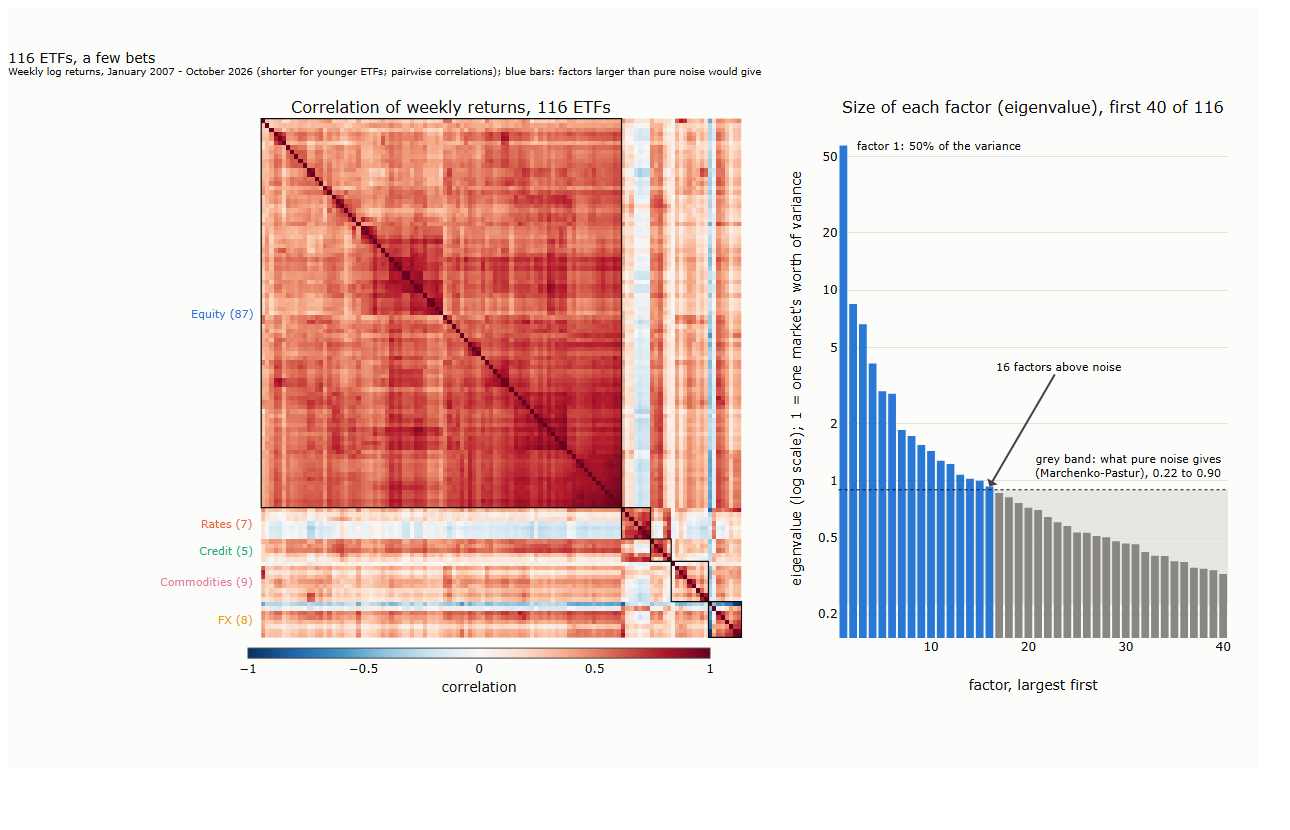

,long-only view,trend follower's view (sign ignored),"Meucci (§3.6, not used)"
each of the ETFs,2.32,2.18,1.07
equity alone,1.71,1.71,1.00
Equity + Rates,2.97,2.48,2.91
Equity + Rates + Commodities,3.80,3.11,3.37
Equity + Rates + Commodities + FX,4.14,3.03,2.47
Equity + Rates + Commodities + FX + Credit,3.70,2.98,2.51
one ETF per class,5.12,2.28,2.82


In [4]:
run("l25_pca_charts.py"); run("l25_pairs.py")
pictures("25_key")
cb = result("class_bets.json"); cols = dict(bets="long-only view", bets_abs="trend follower's view (sign ignored)", enb="Meucci (§3.6, not used)")
rows = {"each of the ETFs": cb["per_etf"], "equity alone": cb["within"]["Equity"]} | {" + ".join(a["classes"]): a for a in cb["adding"][1:]} | {"one ETF per class": cb["one_each"]}
pd.DataFrame({k: {cols[c]: v[c] for c in cols} for k, v in rows.items()}).T.round(2)

## 2. Synchronous closes

Table 2.2: correlation with SPY of daily and weekly log returns, and of the ETF's daily return with SPY's the day before. With stale prices, the weekly correlation would be higher than the daily one and the last column positive.

In [5]:
run("l25_sync.py")
pd.DataFrame(result("sync.json")).T.round(3)

l25_sync.py : 2 s


,daily,weekly,etf_after_spy,etf_before_spy,days
EWJ,0.766,0.743,-0.111,-0.078,4997.0
EWA,0.819,0.816,-0.115,-0.096,4997.0
EWH,0.703,0.626,-0.139,-0.062,4997.0
EWT,0.735,0.681,-0.147,-0.039,4997.0
EWY,0.722,0.689,-0.141,-0.031,4997.0
FXI,0.671,0.591,-0.155,-0.044,4997.0
INDA,0.607,0.562,-0.127,-0.113,3715.0
EWG,0.824,0.812,-0.084,-0.074,4997.0
EWU,0.829,0.830,-0.089,-0.088,4997.0
EWQ,0.825,0.808,-0.087,-0.089,4997.0


## 3. Correlation, factors and noise

### 3.1 Hand checks

Three checks, each a hand calculation against the library value on our data:

1. the noise band of §3.3 from its formula;
2. a loading $`e_{ik}\sqrt{\lambda_k}`$ is the correlation of market $`i`$ with the factor's score (on the ETFs with complete data since 2007, so that every number uses the same weeks);
3. the number of bets of §3.6 step by step for SPY, TLT and GLD, and Meucci's effective number of bets on the same three, which reads them as one bet.

In [6]:
P = result("pca.json"); N, T, l1 = P["n"], P["weeks"], P["eig"][0]
edge = (1 - l1 / N) * (1 + np.sqrt(N / T)) ** 2; low = (1 - l1 / N) * (1 - np.sqrt(N / T)) ** 2
print(f"noise band by hand: {low:.4f} to {edge:.4f}; script: {P['mp_low']:.4f} to {P['mp_edge']:.4f}; factors above it: {sum(e > edge for e in P['eig'])} (script {P['above']})")

G = R["2007":]; G = G.loc[:, G.notna().all()]; Z = (G - G.mean()) / G.std()
v, E = np.linalg.eigh(Z.corr().values); k = np.argmax(v); score = Z.values @ E[:, k] / np.sqrt(v[k])
i = list(G.columns).index("SPY")
print(f"SPY: loading e*sqrt(lambda) = {abs(E[i, k]) * np.sqrt(v[k]):.6f}; correlation of SPY with the factor score = {abs(np.corrcoef(Z['SPY'], score)[0, 1]):.6f} ({G.shape[1]} ETFs)")

X = R.loc["2023":"2025", ["SPY", "TLT", "GLD"]]; Cm = X.corr(); w = np.ones(3) / 3; print(Cm.round(3))
undiv, held = w.sum(), np.sqrt(w @ Cm.values @ w)
print(f"number of bets by hand: ({undiv:.4f} / {held:.4f})^2 = {(undiv / held) ** 2:.6f}; library: {L.bets(Cm):.6f}")
lam, Ev = np.linalg.eigh(Cm.values); expo = Ev.T @ w; risk = expo ** 2 * lam; p = risk / risk.sum()
steps = pd.DataFrame(dict(eigenvalue=lam, exposure=expo, risk=risk, share=p)).round(4)
print(steps); print(f"Meucci's effective bets by hand: {np.exp(-(p * np.log(p)).sum()):.6f}; library: {L.enb(Cm):.6f} (one factor takes {p.max():.0%} of the risk)")

noise band by hand: 0.2235 to 0.8984; script: 0.2235 to 0.8984; factors above it: 16 (script 16)
SPY: loading e*sqrt(lambda) = 0.928648; correlation of SPY with the factor score = 0.928648 (64 ETFs)
       SPY    TLT    GLD
SPY  1.000  0.115  0.050
TLT  0.115  1.000  0.126
GLD  0.050  0.126  1.000
number of bets by hand: (1.0000 / 0.6310)^2 = 2.511294; library: 2.511294
   eigenvalue  exposure    risk   share
0      0.8521    0.0552  0.0026  0.0065
1      0.9499   -0.0150  0.0002  0.0005
2      1.1979   -0.5745  0.3954  0.9929
Meucci's effective bets by hand: 1.044852; library: 1.044852 (one factor takes 99% of the risk)


### 3.2 The factors and co-movement over time

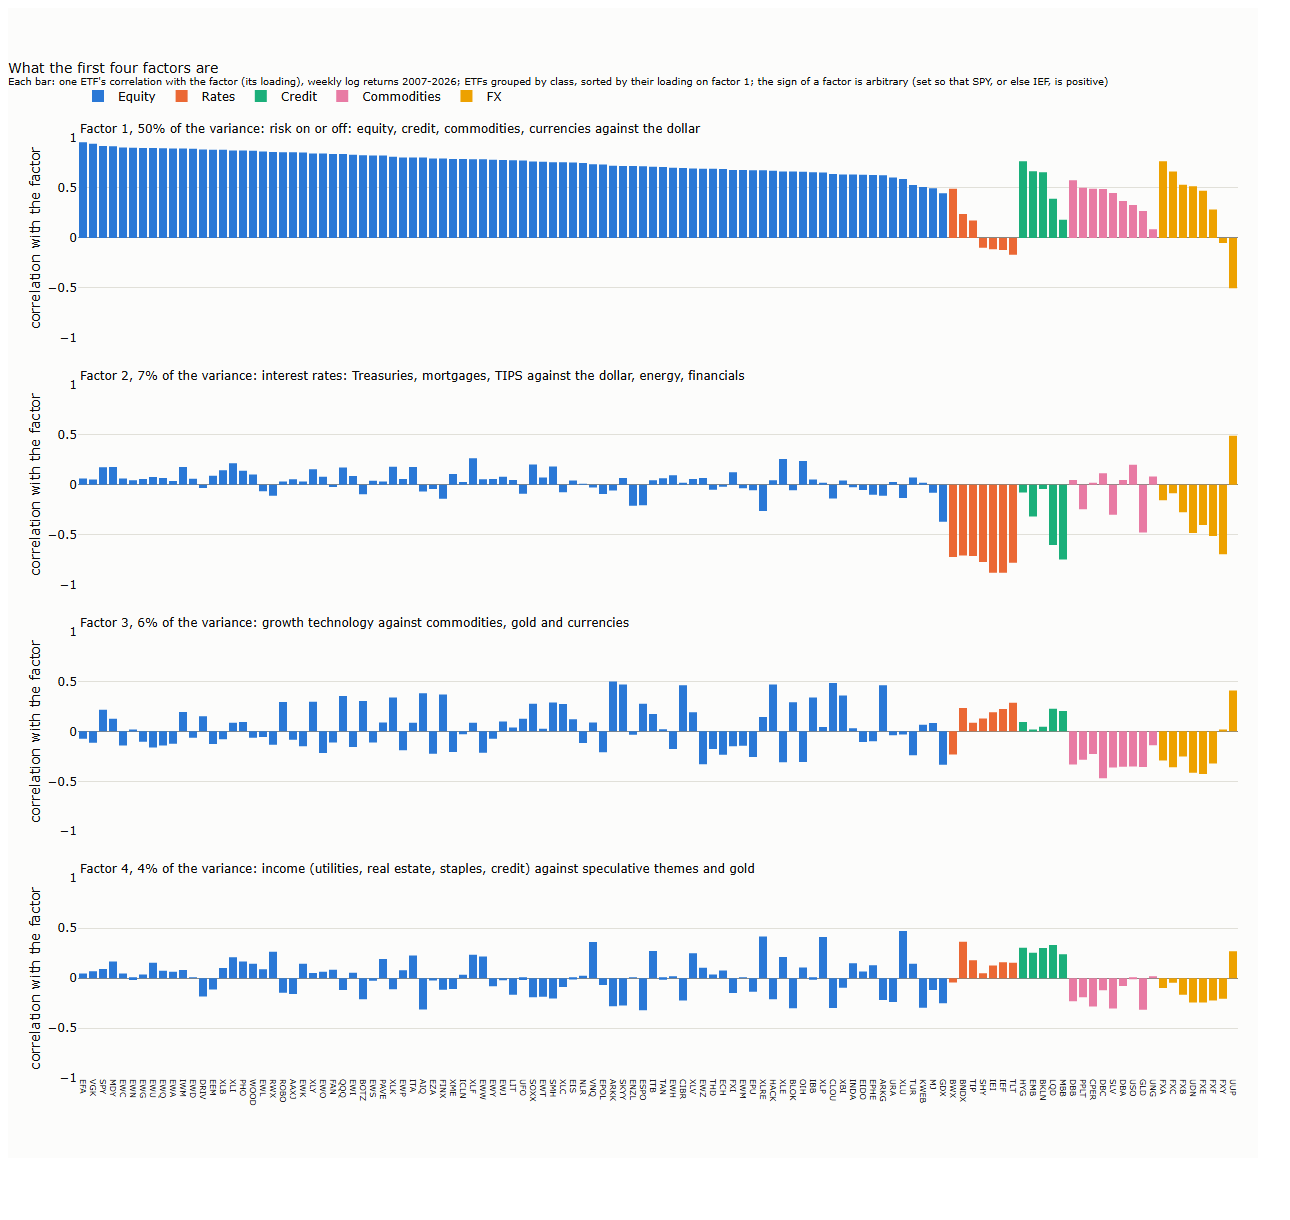

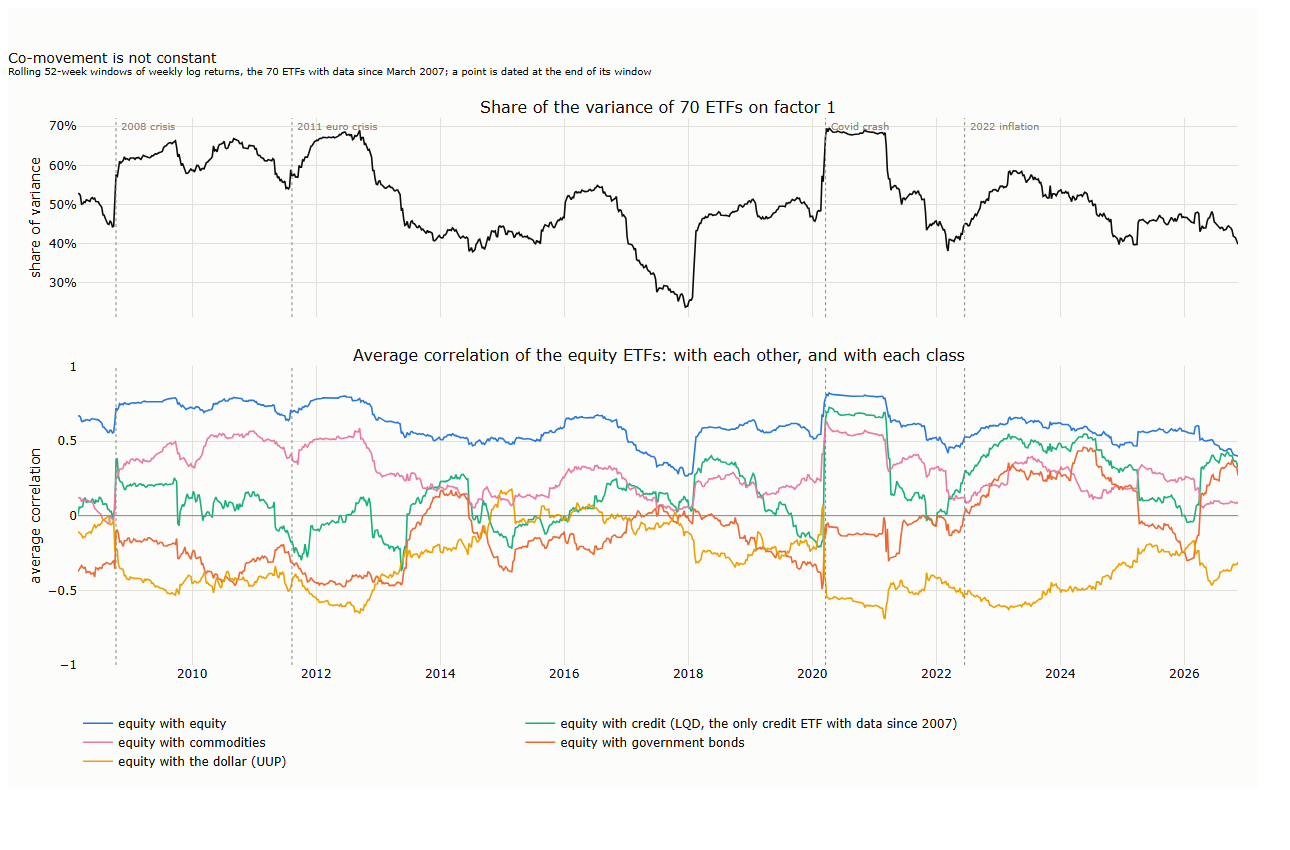

,factor 1 share,equity with bonds,equity with the dollar
lowest,0.237095,-0.491854,-0.69123
on,2017-12-15,2020-02-28,2021-03-05
highest,0.695534,0.458136,0.179871
on,2020-04-10,2024-05-17,2015-02-27


In [7]:
pictures("25_factors", "25_comovement")
Q = pd.read_csv(WORK / "comovement.csv", index_col=0, parse_dates=True)
pd.DataFrame({"factor 1 share": [Q.share1.min(), Q.share1.idxmin().date(), Q.share1.max(), Q.share1.idxmax().date()],
              "equity with bonds": [Q.Rates.min(), Q.Rates.idxmin().date(), Q.Rates.max(), Q.Rates.idxmax().date()],
              "equity with the dollar": [Q.dollar.min(), Q.dollar.idxmin().date(), Q.dollar.max(), Q.dollar.idxmax().date()]},
             index=["lowest", "on", "highest", "on"])

## 4. The same market?

### 4.1 Hand checks: concordance and the efficiency ratio

The concordance of FXE and UUP in 2023-2025, counted week by week, against the library; and the efficiency ratio of SPY on one date, by hand against Kaufman's efficiency ratio in `trading_models` (which fills its first weeks with zero, so the date is well past them).

In [8]:
X = L.window(R, pd.Timestamp("2025-12-31")); Ph = PH.loc[X.index, ["FXE", "UUP"]].dropna(); Ph = Ph[(Ph != 0).all(axis=1)]
same = (Ph.FXE == Ph.UUP).mean()
print(f"FXE and UUP, {len(Ph)} weeks: same phase {same:.4f}, opposite {1 - same:.4f}; concordance (sign ignored) by hand {max(same, 1 - same):.4f}, library {L.concordance(PH.loc[X.index], 'FXE', 'UUP'):.4f}")
print(f"weekly correlation {X.FXE.corr(X.UUP):.3f}; yearly log return 2023-2025: UUP {52 * R.loc['2023':'2025', 'UUP'].mean():.3%}, FXE {52 * R.loc['2023':'2025', 'FXE'].mean():.3%}")

from trading_models.trend_following.data.schema import InstrumentPanel
from trading_models.trend_following.signals.baselines import efficiency_ratio
Wk = close.resample("W-FRI").last()[["SPY"]]; day = pd.Timestamp("2020-06-05"); j = Wk.index.get_loc(day)
win = Wk.SPY.iloc[j - 26:j + 1]; net = abs(win.iloc[-1] - win.iloc[0]); path = win.diff().abs().sum()
print(f"SPY on {day.date()}: net move {net:.4f}, path {path:.4f}, efficiency ratio by hand {net / path:.6f}, package {efficiency_ratio(InstrumentPanel(close=Wk), window=26).SPY.loc[day]:.6f}")

FXE and UUP, 156 weeks: same phase 0.4487, opposite 0.5513; concordance (sign ignored) by hand 0.5513, library 0.5513
weekly correlation -0.962; yearly log return 2023-2025: UUP 3.632%, FXE 4.751%


SPY on 2020-06-05: net move 7.1725, path 252.0444, efficiency ratio by hand 0.028457, package 0.028457


### 4.2 Concordance and trend strength across all pairs

l25_trend_strength.py : 4 s


l25_more_charts.py : 7 s


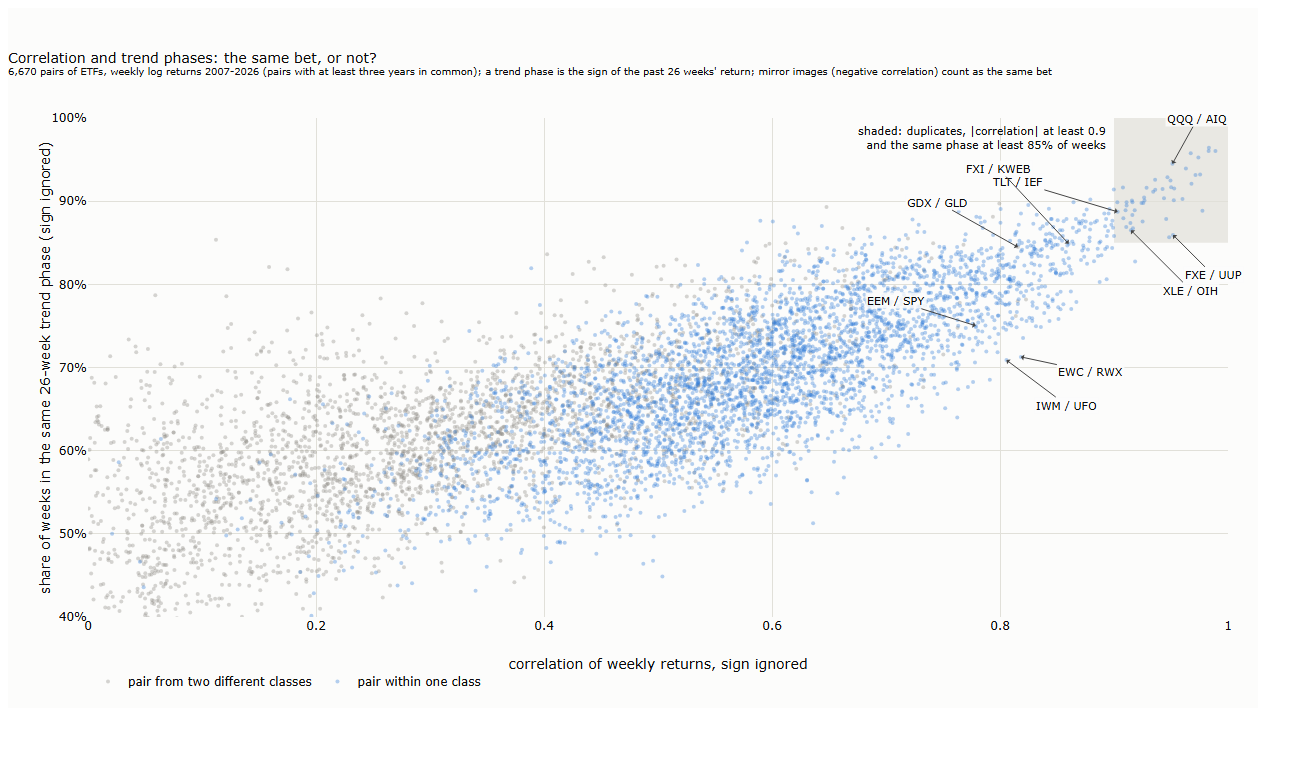

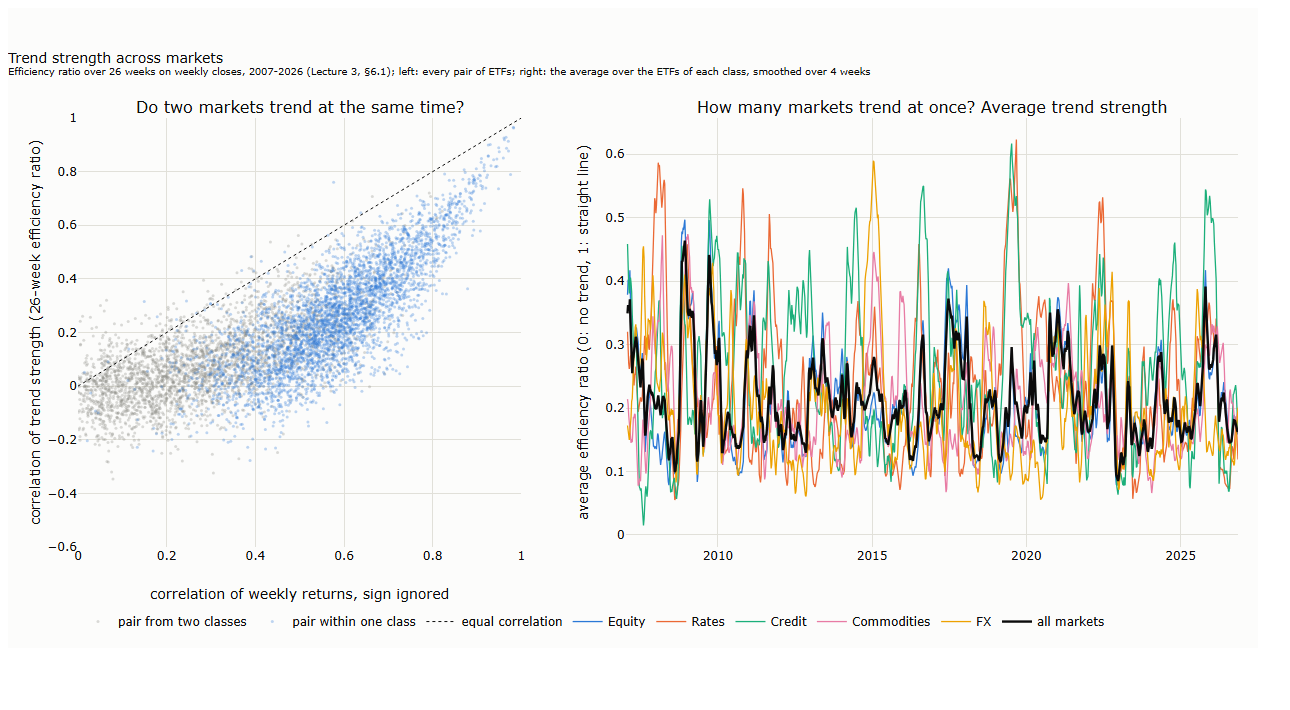

,pairs,same_phase,below_80,hedge_drift
band,,,,
"[0.0, 0.5)",3532,0.603,0.997,0.036
"[0.5, 0.7)",2279,0.700,0.938,0.037
"[0.7, 0.8)",566,0.776,0.677,0.031
"[0.8, 0.9)",245,0.831,0.278,0.032
"[0.9, 1.0)",48,0.901,0.000,0.016


er_corr_mean        0.190
ret_abscorr_mean    0.454
er_corr_within      0.264
er_corr_across      0.089
er_share1           0.246
ret_share1          0.496
dtype: float64

In [9]:
run("l25_trend_strength.py"); run("l25_more_charts.py")
pictures("25_concordance", "25_trend_strength")
Pp = pd.read_parquet(WORK / "pairs.parquet"); Pp["band"] = pd.cut(Pp.rho.abs(), [0, 0.5, 0.7, 0.8, 0.9, 1.0], right=False)
tab = Pp.groupby("band", observed=True).agg(pairs=("conc", "size"), same_phase=("conc", "median"), below_80=("conc", lambda c: (c < 0.8).mean()),
                                            hedge_drift=("hedge_drift", lambda d: d.abs().median()))
ts = result("trend_strength.json")
display(tab.round(3)); pd.Series({k: ts[k] for k in ("er_corr_mean", "ret_abscorr_mean", "er_corr_within", "er_corr_across", "er_share1", "ret_share1")}).round(3)

## 5. The methods as a family

The screen of the seven methods fixed before any result (`l25_screen.py`, rerun with `RUN_ALL`): the vote, the cluster counts, the spanning tree, the graphical lasso and downside correlation.

majority vote: markets kept at the first and the last review: 28 80
groups, average linkage, 2007-2026: {'average_0.30': 4, 'average_0.40': 8, 'average_0.50': 13, 'average_0.60': 22, 'average_0.70': 49, 'average_0.75': 57, 'average_0.80': 68, 'average_0.85': 82, 'average_0.90': 96}
the same after random-matrix cleaning, end-2025 window: {'rmt_average_0.70': 70, 'rmt_average_0.75': 105, 'rmt_average_0.80': 116, 'rmt_average_0.85': 116, 'rmt_average_0.90': 116}
spanning tree hubs: {'EEM': 11, 'VGK': 11, 'MDY': 10, 'EFA': 9} | leaves: 64 of 116
graphical lasso, isolated markets per penalty: {'0.05': 0, '0.1': 0, '0.2': 0, '0.3': 0, '0.5': 0}


,all,down,normal
g,,,
both equity,0.59,0.64,0.25
equity and other,0.32,0.53,0.08
neither,0.34,0.40,0.10


sell-off weeks: {'sell_weeks': 115, 'n': 116, 'clusters_all': 68, 'clusters_sell': 77}


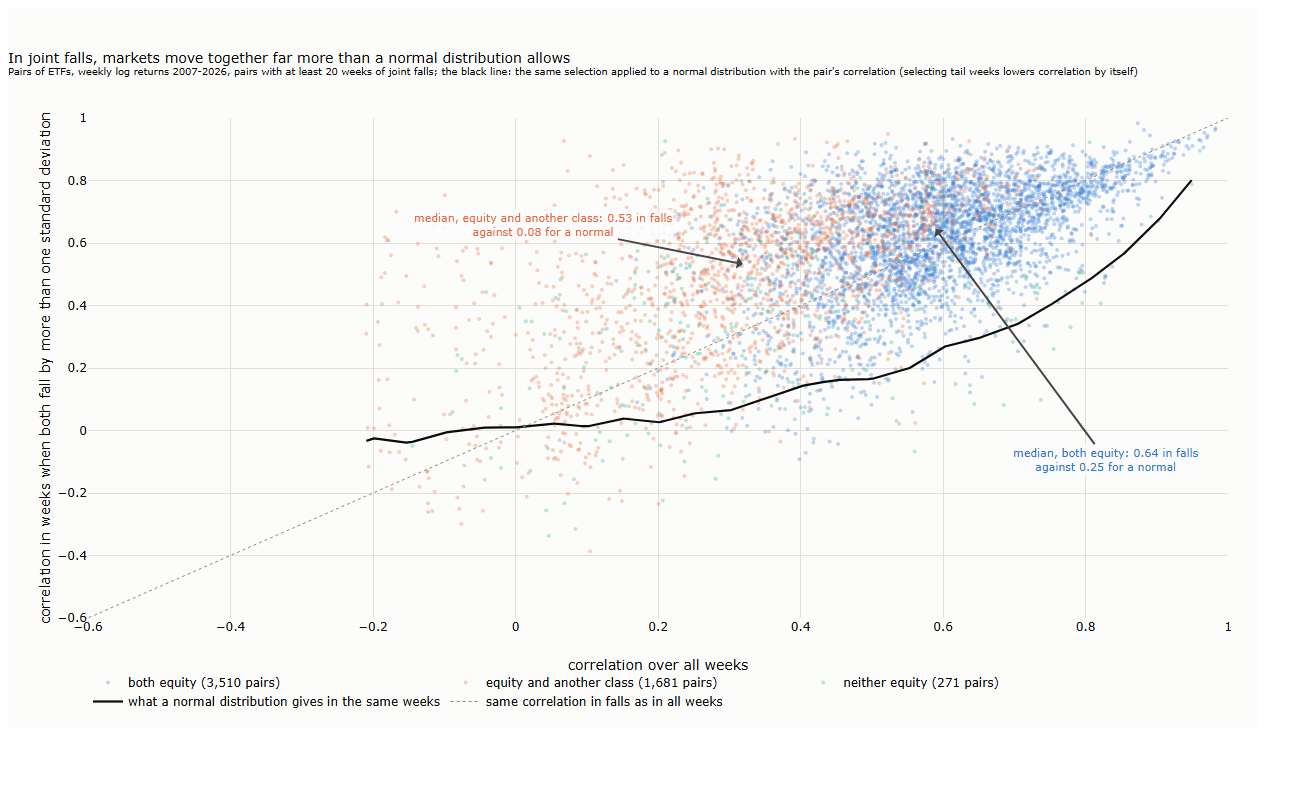

In [10]:
S = result("screen.json")
print("majority vote: markets kept at the first and the last review:", len(S["reviews"]["2009"]["consensus"]), len(S["reviews"]["2025"]["consensus"]))
print("groups, average linkage, 2007-2026:", {k: v for k, v in S["full"]["nclust"].items() if k.startswith("average")})
print("the same after random-matrix cleaning, end-2025 window:", {k: v for k, v in S["reviews"]["2025"]["nclust"].items() if k.startswith("rmt_average")})
m = pd.DataFrame(S["mst"]).T; print("spanning tree hubs:", m.degree.astype(int).nlargest(4).to_dict(), "| leaves:", int((m.degree == 1).sum()), "of", len(m))
print("graphical lasso, isolated markets per penalty:", {a: (d if isinstance(d, str) else sum(v == 0 for v in d.values())) for a, d in S["glasso_degree"].items()})
D = pd.DataFrame(S["downside_pairs"]); D["g"] = np.where((D.ca == "Equity") & (D.cb == "Equity"), "both equity", np.where((D.ca == "Equity") | (D.cb == "Equity"), "equity and other", "neither"))
display(D.groupby("g")[["all", "down", "normal"]].median().round(2)); print("sell-off weeks:", S["stress"])
pictures("25_downside")

## 6. Slots per class

The slots per class at each review (factors above the noise band in the class) and the minimum of 2.

In [11]:
F = result("fill.json")
caps = pd.DataFrame({y: r["caps"] for y, r in F["reviews"].items()}).T
caps.assign(total=caps.sum(axis=1))

,Equity,Rates,Credit,Commodities,FX,total
2009,7,3,2,3,2,17
2010,8,3,2,3,2,18
2011,7,2,2,3,3,17
2012,7,2,2,3,3,17
2013,6,3,2,3,3,17
2014,6,3,2,3,3,17
2015,6,3,2,3,4,18
2016,7,3,2,3,3,18
2017,7,3,2,3,3,18
2018,6,3,2,3,3,17


## 7. Filling the slots

### 7.1 The score's first pick in equity, pillar by pillar

At the end-2025 review, every equity ETF above the floor is ranked on representativeness and liquidity (the first pick has nothing to diversify against). SPY leads although EFA is slightly more representative.

In [12]:
import l25_fill as Fm
end = pd.Timestamp("2025-12-31"); Xw = L.window(R, end); Cw = L.corr(Xw, L.MINW); liq = L.liquidity(dv, end); Fm.LIQ.clear(); Fm.LIQ.update(liq)
eq = [x for x in Cw.index if L.CLASS[x] == "Equity"]; cand = [x for x in eq if liq.get(x, 0) >= L.FLOOR]
df = pd.DataFrame(index=cand); df["explained"] = [L.explained(Cw, [x], eq) for x in cand]; df["USD m a day"] = [liq[x] / 1e6 for x in cand]
df["rank, representativeness"] = df.explained.rank(pct=True); df["rank, liquidity"] = df["USD m a day"].rank(pct=True)
df["score"] = Fm.composite("sc_div", Cw, [], cand, eq)
df.sort_values("score", ascending=False).head(8).round(3)

,explained,USD m a day,"rank, representativeness","rank, liquidity",score
SPY,0.442,41488.499,0.968,1.000,0.984
IWM,0.412,6924.683,0.887,0.968,0.927
EFA,0.471,1172.105,1.000,0.823,0.911
XLI,0.410,1380.158,0.855,0.887,0.871
QQQ,0.363,24899.265,0.742,0.984,0.863
EEM,0.413,1162.905,0.903,0.806,0.855
MDY,0.425,453.258,0.935,0.629,0.782
XLK,0.334,1465.208,0.629,0.903,0.766


### 7.2 Out of sample, and the weights

,ev,abs,pos,"liquidity, USD m"
greedy diversification,0.745 (16),0.292 (16),0.194 (14),263
one market per factor,0.745 (16),0.333 (13),0.201 (14),149
explained variance,0.773 (17),0.334 (10),0.204 (12),264
key market + greedy,0.757 (17),0.313 (15),0.207 (11),197
score (chosen),0.754 (17),0.303 (16),0.191 (14),399


,ev,abs,pos,"liquidity, USD m"
a third each,0.750 (16),0.306 (15),0.195 (14),399
"0.5, 0.25, 0.25",0.756 (17),0.327 (14),0.204 (14),270
"0.25, 0.5, 0.25",0.754 (17),0.303 (16),0.191 (14),399
"0.25, 0.25, 0.5",0.757 (17),0.322 (14),0.201 (13),529
"0.2, 0.6, 0.2",0.756 (16),0.303 (16),0.197 (13),399
"0.2, 0.5, 0.3",0.754 (16),0.303 (16),0.191 (13),399
"0.15, 0.7, 0.15",0.758 (16),0.312 (16),0.192 (14),278


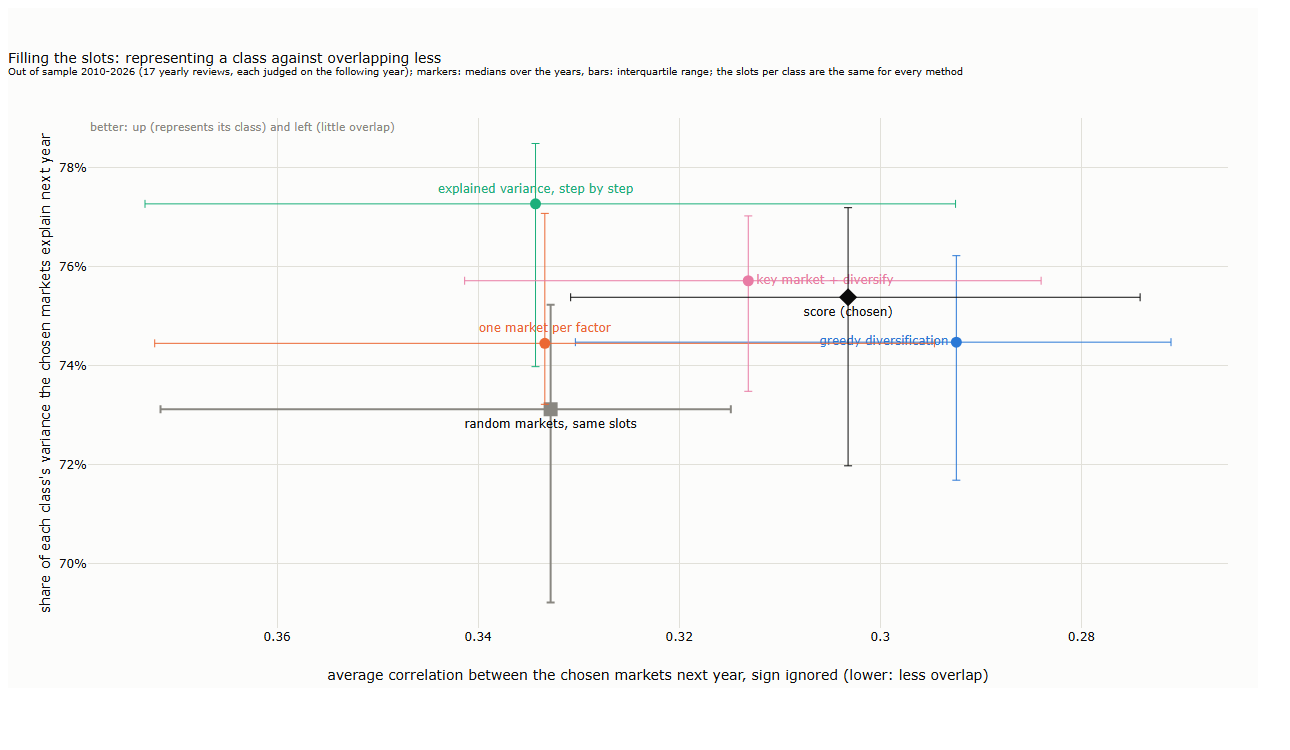

{'Equity': ['SPY', 'GDX', 'SMH', 'XLV', 'FXI', 'EWT', 'XLU', 'EWZ'],
 'Rates': ['TLT', 'SHY', 'TIP', 'BNDX'],
 'Credit': ['LQD', 'HYG'],
 'Commodities': ['USO', 'GLD', 'UNG'],
 'FX': ['FXE', 'FXY', 'UUP']}

In [13]:
O = pd.DataFrame(F["oos"]); G = pd.DataFrame(result("fill_grid.json")["oos"])
def row(D_, m):
    return {c: f"{D_[f'{m}_{c}'].median():.3f} ({int((D_[f'{m}_{c}_beats'] > .5).sum())})" for c in ("ev", "abs", "pos")} | {"liquidity, USD m": round(10 ** D_[f"{m}_liq"].median() / 1e6)}
names = {"dr": "greedy diversification", "pc": "one market per factor", "ev": "explained variance", "hy": "key market + greedy", "sc_div": "score (chosen)"}
display(pd.DataFrame({names[m]: row(O, m) for m in names}).T)
W_ = {"sc": "a third each", "sc_rep": "0.5, 0.25, 0.25", "sc_div": "0.25, 0.5, 0.25", "sc_liq": "0.25, 0.25, 0.5"}
display(pd.DataFrame({W_[m]: row(O, m) for m in W_} | {w: row(G, m) for m, w in (("sc_d60", "0.2, 0.6, 0.2"), ("sc_d50l30", "0.2, 0.5, 0.3"), ("sc_d70", "0.15, 0.7, 0.15"))}).T)
pictures("25_tradeoff")
F["reviews"]["2025"]["sc_div"]

## 8. A roadmap for growing capital

l25_roadmap.py : 4 s


l25_roadmap_path.py : 4 s


l25_roadmap_chart.py : 3 s


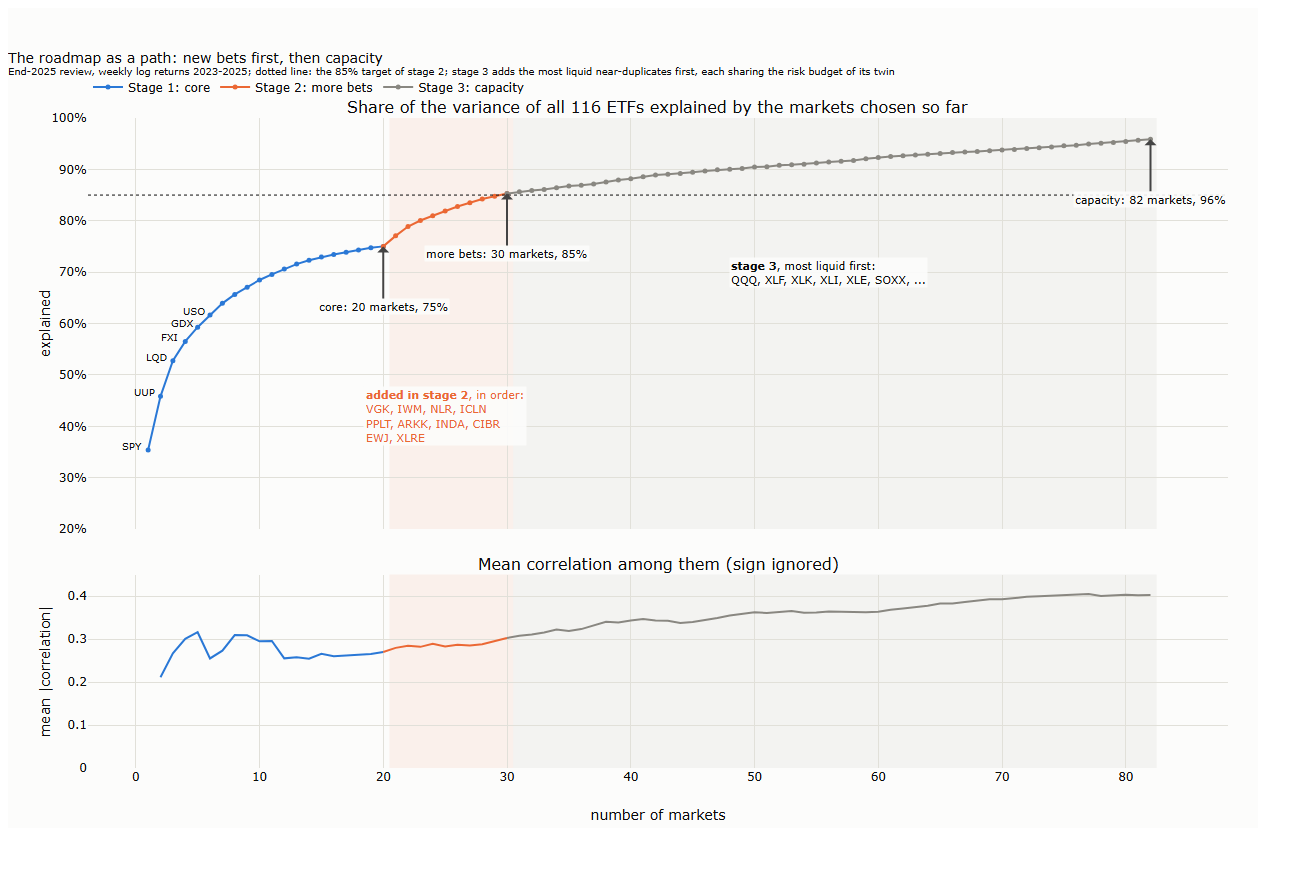

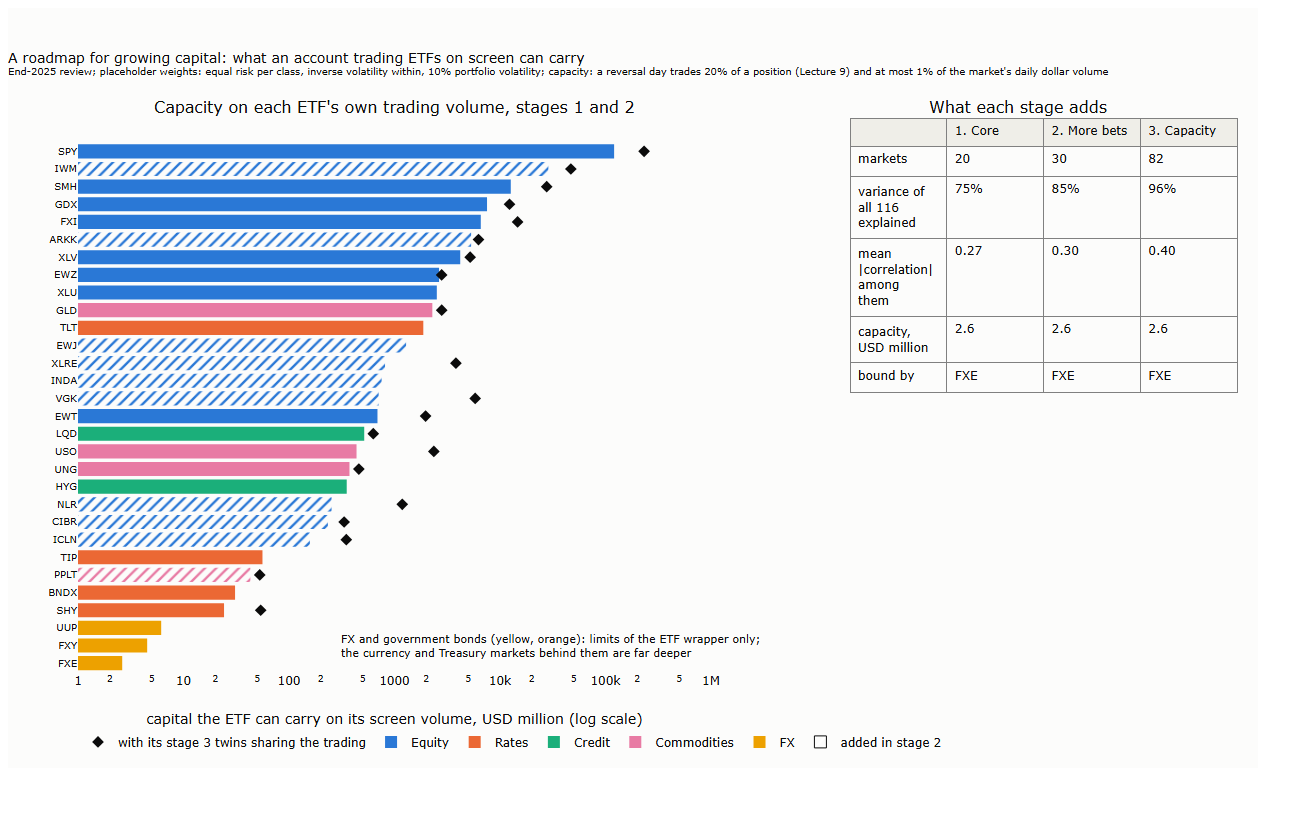

,markets,explained,overlap,capacity_usd_m,bound_by
1 core,20,0.75,0.27,2.6,FXE
2 more bets,30,0.853,0.3,2.6,FXE
3 capacity,82,0.959,0.4,2.6,FXE


In [14]:
run("l25_roadmap.py"); run("l25_roadmap_path.py"); run("l25_roadmap_chart.py")
pictures("25_roadmap_path", "25_roadmap")
pd.DataFrame({k: dict(markets=v["n"], explained=round(v["explained_all"], 3), overlap=round(v["mean_abs"], 2), capacity_usd_m=round(v["capacity_usd"] / 1e6, 1), bound_by=v["binding"])
              for k, v in result("roadmap.json")["stages"].items()}).T

**Shipped against recomputed.** The quick steps above were rerun from the data; their key numbers against the shipped results. With the same download they match exactly; a later download can differ slightly.

In [15]:
pd.concat([compare("pca.json", ["mp_edge", "above"]), compare("class_bets.json", ["per_etf.bets", "per_class.bets_abs", "one_each.bets"]),
           compare("trend_strength.json", ["er_corr_mean", "er_corr_across", "universe.er_corr"]),
           compare("roadmap.json", ["stages.1 core.explained_all", "stages.2 more bets.n", "stages.3 capacity.mean_abs"])], ignore_index=True)

,number,shipped,recomputed
0,mp_edge,0.898363,0.898363
1,above,16.000000,16.000000
2,per_etf.bets,2.320472,2.320472
3,per_class.bets_abs,2.978354,2.978354
4,one_each.bets,5.115871,5.115871
5,er_corr_mean,0.189824,0.189824
6,er_corr_across,0.089036,0.089036
7,universe.er_corr,0.110875,0.110875
8,stages.1 core.explained_all,0.750156,0.750156
9,stages.2 more bets.n,30.000000,30.000000


## 9. A test of your own

Change one setting and see what moves, for example the liquidity floor, the duplicate rule or the score's weights in `scripts/l25.py` and `scripts/l25_fill.py`, then rerun §7 with `RUN_ALL`. Any change made after looking at results should be dated in `results/hypotheses.md` before it is judged on later data, as every change of this lecture was.